
--- T = 500 esantioane, n = 1000 ---
           X1        X2        X3     X1000     x_bar
t=1  4.808417  4.672379  4.769522  0.770389  2.028716
t=2  0.455538  0.634410  0.255694  0.850169  2.031244
t=3  2.519497  2.335460  0.305659  1.901677  2.003320
t=4  5.249464  3.002088  2.002670  2.145129  1.937229
t=5  0.240679  0.457523  0.118307  3.850721  1.837095
Media mediilor = 1.9962 (teoretic 2.0), abaterea standard = 0.0632 (teoretic 0.0632)

--- T = 1000 esantioane, n = 1000 ---
           X1        X2        X3     X1000     x_bar
t=1  2.328470  0.317695  0.330020  0.015640  2.114093
t=2  1.656754  3.909814  0.273206  2.218537  1.982805
t=3  0.592781  0.123863  0.129746  0.268224  1.982166
t=4  3.542914  2.749097  1.505579  0.889561  1.992059
t=5  3.559285  4.702826  2.988732  0.730562  2.073480
Media mediilor = 1.9995 (teoretic 2.0), abaterea standard = 0.0630 (teoretic 0.0632)


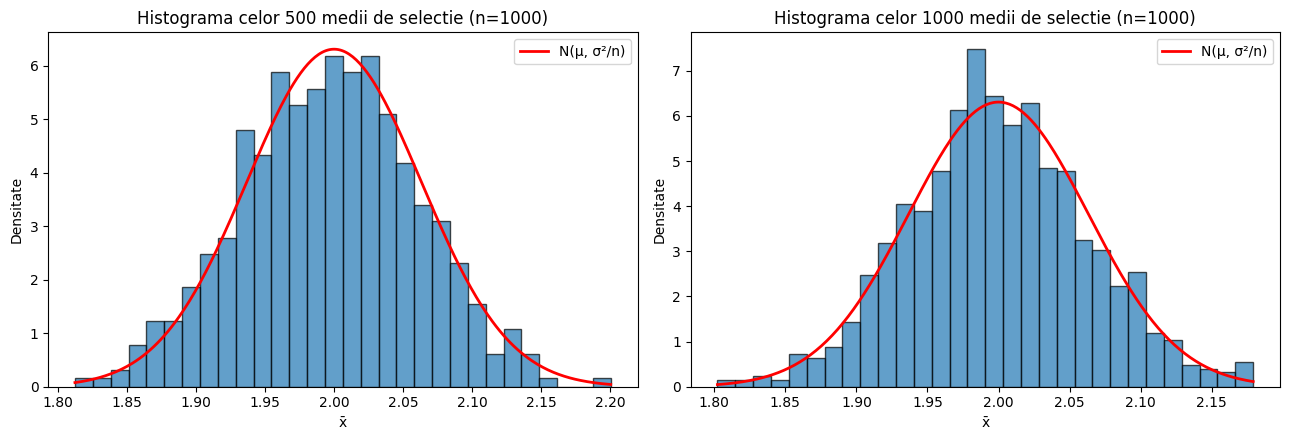


=== a) Overview ===
Dimensiune: (463, 19)
  minority  age  gender credits    beauty  eval division native tenure  \
0      yes   36  female    more  0.289916   4.3    upper    yes    yes   
1      yes   36  female    more  0.289916   3.7    upper    yes    yes   
2      yes   36  female    more  0.289916   3.6    upper    yes    yes   
3      yes   36  female    more  0.289916   4.4    upper    yes    yes   
4       no   59    male    more -0.737732   4.5    upper    yes    yes   

   students  allstudents  prof  PrimaryLast  vismin  female  single_credit  \
0        24           43     1            0       1       1              0   
1        86          125     1            0       1       1              0   
2        76          125     1            0       1       1              0   
3        77          123     1            1       1       1              0   
4        17           20     2            0       0       0              0   

   upper_division  English_speaker  tenured

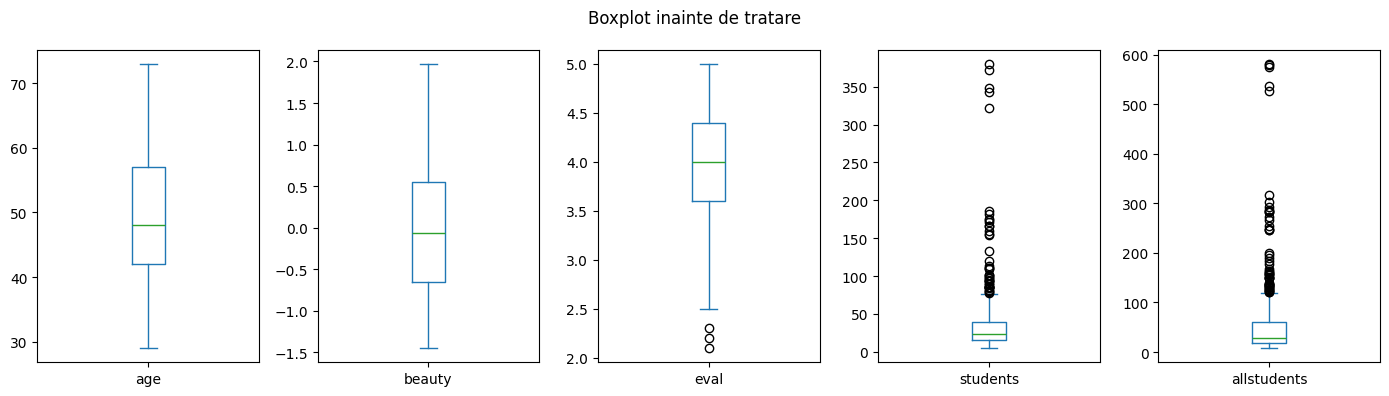


Dupa winsorizare:
             count       mean        std   min   25%   50%   75%    max
age          463.0  48.365011   9.802742  29.0  42.0  48.0  57.0   73.0
students     463.0  30.617711  21.427459   5.0  15.0  23.0  40.0   77.5
allstudents  463.0  44.254860  34.928852   8.0  19.0  29.0  60.0  121.5

Media evaluarilor pentru primii 10 profesori:
prof
1     4.000000
2     3.533333
3     3.450000
4     4.012500
5     4.350000
6     4.442857
7     3.840000
8     4.028571
9     4.257143
10    4.560000
Name: eval, dtype: float64


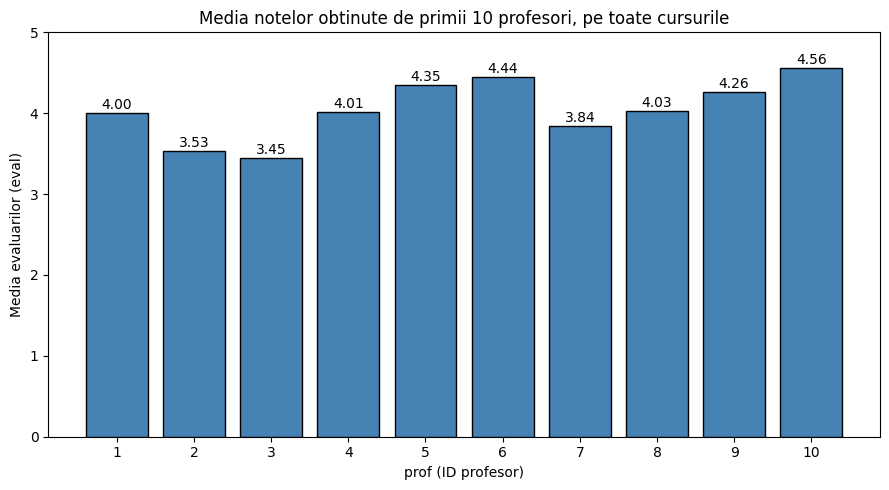

In [5]:
"""
Lab 2 FDSAI 2026-2027
Dependente: pip install numpy pandas matplotlib seaborn
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

rng = np.random.default_rng(42)

# =====================================================================
# EXERCITIUL 1 - Distributia mediilor de selectie (Teorema Limita Centrala)
# =====================================================================
n = 1000                      # observatii intr-un esantion
distributie = "exponentiala"  # asimetrica -> se vede clar efectul CLT


def genereaza_esantioane(T, n):
    """Returneaza un DataFrame T x n (linii = esantioane) + coloana cu media."""
    X = rng.exponential(scale=2.0, size=(T, n))          # Exp(lambda=1/2): media=2, sd=2
    df = pd.DataFrame(X, columns=[f"X{i}" for i in range(1, n + 1)])
    df.index = [f"t={t}" for t in range(1, T + 1)]
    df["x_bar"] = X.mean(axis=1)                          # media de selectie pe fiecare linie
    return df


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, T in zip(axes, (500, 1000)):
    tabel = genereaza_esantioane(T, n)
    print(f"\n--- T = {T} esantioane, n = {n} ---")
    print(tabel[["X1", "X2", "X3", "X1000", "x_bar"]].head())
    medii = tabel["x_bar"]

    ax.hist(medii, bins=30, density=True, edgecolor="black", alpha=0.7)
    # densitatea normala teoretica din CLT: N(mu, sigma^2 / n)
    mu, sigma = 2.0, 2.0
    xs = np.linspace(medii.min(), medii.max(), 300)
    ax.plot(xs, np.exp(-(xs - mu) ** 2 / (2 * sigma**2 / n)) /
            np.sqrt(2 * np.pi * sigma**2 / n), "r-", lw=2, label="N(μ, σ²/n)")
    ax.set_title(f"Histograma celor {T} medii de selectie (n={n})")
    ax.set_xlabel("x̄")
    ax.set_ylabel("Densitate")
    ax.legend()
    print(f"Media mediilor = {medii.mean():.4f} (teoretic {mu}), "
          f"abaterea standard = {medii.std(ddof=1):.4f} (teoretic {sigma/np.sqrt(n):.4f})")

plt.tight_layout()
plt.savefig("ex1_histograme.png", dpi=150)
plt.show()

# Observatie: desi datele initiale sunt exponentiale (puternic asimetrice),
# mediile de selectie au o distributie aproximativ normala, centrata in mu = 2,
# cu abaterea standard ~ sigma/sqrt(n). Cu cat T creste, histograma se apropie
# mai mult de clopotul lui Gauss (Teorema Limita Centrala + Legea Numerelor Mari).

# =====================================================================
# EXERCITIUL 2 - Pregatirea setului de date
# =====================================================================
LOCAL_PATH = "/content/teachingratings.csv"
URL = ("https://cf-courses-data.s3.us.cloud-objectstorage.appdomain.cloud/"
       "IBMDeveloperSkillsNetwork-ST0151ENSkillsNetwork/labs/teachingratings.csv")

if os.path.exists(LOCAL_PATH):
    df = pd.read_csv(LOCAL_PATH)
else:
    df = pd.read_csv(URL)

# ---- a) Privire de ansamblu + tipul variabilelor -----------------------
print("\n=== a) Overview ===")
print("Dimensiune:", df.shape)
print(df.head())
df.info()
print(df.describe(include="all").T)
print("Valori lipsa:\n", df.isna().sum())

# Tipuri statistice (interpretare, nu doar dtype-ul pandas):
tipuri = {
    "minority":    "calitativa nominala (binara: yes/no)",
    "age":         "cantitativa discreta (varsta in ani, scala de raport)",
    "gender":      "calitativa nominala (binara: male/female)",
    "credits":     "calitativa nominala (binara: single/more)",
    "beauty":      "cantitativa continua (scor standardizat, scala de interval)",
    "eval":        "cantitativa continua (nota 1-5; strict vorbind ordinala, tratata ca numerica)",
    "division":    "calitativa nominala (binara: upper/lower)",
    "native":      "calitativa nominala (binara: yes/no)",
    "tenure":      "calitativa nominala (binara: yes/no)",
    "students":    "cantitativa discreta (nr. studenti care au evaluat)",
    "allstudents": "cantitativa discreta (nr. studenti inscrisi)",
    "prof":        "calitativa nominala (identificator profesor, desi stocat ca intreg)",
}
print("\nTipul variabilelor:")
for col in df.columns:
    print(f"  {col:12s} dtype={str(df[col].dtype):8s} -> {tipuri.get(col, '?')}")

# ---- b) Codificarea variabilelor categoriale ---------------------------
print("\n=== b) Encoding ===")
df_enc = df.copy()
binare = {
    "minority": {"no": 0, "yes": 1},
    "gender":   {"female": 0, "male": 1},
    "credits":  {"single": 0, "more": 1},
    "division": {"lower": 0, "upper": 1},
    "native":   {"no": 0, "yes": 1},
    "tenure":   {"no": 0, "yes": 1},
}
for col, mapare in binare.items():
    df_enc[col] = df_enc[col].map(mapare).astype(int)
    print(f"{col}: {mapare}")
# 'prof' este deja numeric, dar e doar un ID -> NU o folosim ca variabila numerica in modele.
print(df_enc.head())
print(df_enc.dtypes)

# ---- c) Outlieri -------------------------------------------------------
# Metoda aleasa: regula IQR (Tukey): outlier daca x < Q1 - 1.5*IQR sau x > Q3 + 1.5*IQR.
# Justificare: nu presupune normalitate (students/allstudents sunt puternic asimetrice,
# deci Z-score ar fi nepotrivit), se bazeaza pe cuartile (robuste) si este simpla/interpretabila.
# Tratare: winsorizare (limitare la fence-uri) in loc de stergere, ca sa pastram toate
# cele 463 de randuri (esantion mic) si sa nu pierdem informatia despre profesori.
# Variabilele 'eval' si 'beauty' sunt doar RAPORTATE: valorile extreme sunt note/scoruri
# legitime pe o scala marginita, nu erori de masurare -> le pastram.
print("\n=== c) Outlieri (IQR) ===")
coloane_numerice = ["age", "beauty", "eval", "students", "allstudents"]


def limite_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


for col in coloane_numerice:
    lo, hi = limite_iqr(df_enc[col])
    n_out = ((df_enc[col] < lo) | (df_enc[col] > hi)).sum()
    print(f"{col:12s} limite=({lo:.2f}, {hi:.2f})  outlieri={n_out}")

df_enc[coloane_numerice].plot(kind="box", subplots=True, layout=(1, 5),
                              figsize=(14, 4), title="Boxplot inainte de tratare")
plt.tight_layout()
plt.savefig("ex2_boxplot_inainte.png", dpi=150)
plt.show()

df_clean = df_enc.copy()
for col in ["age", "students", "allstudents"]:      # variabilele tratate
    lo, hi = limite_iqr(df_clean[col])
    df_clean[col] = df_clean[col].clip(lower=lo, upper=hi)

print("\nDupa winsorizare:")
print(df_clean[["age", "students", "allstudents"]].describe().T)

# =====================================================================
# EXERCITIUL 3 - Media notelor pe profesor (primii 10)
# =====================================================================
# Un profesor apare pe mai multe randuri (cate unul pentru fiecare curs),
# deci media se calculeaza cu groupby. 'eval' nu a fost modificata la pasul c).
prime_10 = df_clean["prof"].drop_duplicates().head(10)       # primele 10 valori distincte
medii_prof = (df_clean[df_clean["prof"].isin(prime_10)]
              .groupby("prof")["eval"].mean()
              .reindex(prime_10))
print("\nMedia evaluarilor pentru primii 10 profesori:")
print(medii_prof)

plt.figure(figsize=(9, 5))
plt.bar(medii_prof.index.astype(str), medii_prof.values,
        edgecolor="black", color="steelblue")
plt.xlabel("prof (ID profesor)")
plt.ylabel("Media evaluarilor (eval)")
plt.title("Media notelor obtinute de primii 10 profesori, pe toate cursurile")
plt.ylim(0, 5)
for i, v in enumerate(medii_prof.values):
    plt.text(i, v + 0.05, f"{v:.2f}", ha="center")
plt.tight_layout()
plt.savefig("ex3_medii_profesori.png", dpi=150)
plt.show()